# 03 · Calibration, cost-based threshold, SHAP

Phase 3 turns the Phase 2 model into something a lender could actually use:

1. **Calibration:** do predicted probabilities match real default rates?
2. **Cost-based threshold:** where should the approve/reject line sit, given what a default costs?
3. **Explainability:** which features drive risk, globally and for one applicant, plus a segment check.
4. **Save artifacts** (model, calibrator, threshold) for the Phase 4 API.

The 20% test split stays untouched until section 5. Every choice (calibrator, threshold) is made on out-of-fold predictions from the training split only.
Needs `train_features.parquet` from notebook 02. Expect about 10 minutes in total.

In [18]:
!pip install -q shap

## 1. Setup and data

In [19]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=UserWarning)

# ---- EDIT THIS: where notebook 02 saved the parquet ---------------------------
USE_DRIVE = False
DRIVE_OUT = "/content/drive/MyDrive/credit-risk/data/processed"
DRIVE_MODELS = "/content/drive/MyDrive/credit-risk/models"
# If you kept the parquet in the Colab session instead: USE_DRIVE = False
# -------------------------------------------------------------------------------

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT, MODEL_DIR = Path(DRIVE_OUT), Path(DRIVE_MODELS)
else:
    OUT, MODEL_DIR = Path("/content"), Path("/content/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

PARQUET = OUT / "train_features.parquet"
assert PARQUET.exists(), f"{PARQUET} not found. Run notebook 02 first."
ID_COL = "SK_ID_CURR"

In [20]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

full = pd.read_parquet(PARQUET)
X = full.drop(columns=["TARGET", ID_COL])
y = full["TARGET"]
cat_cols = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
for c in cat_cols:
    X[c] = X[c].astype("category")

# identical split to Phases 1 and 2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
y_tr = y_train.to_numpy()
print("train:", X_train.shape, "| test:", X_test.shape, "| default rate:", round(y_tr.mean(), 4))

lgb_params = dict(n_estimators=500, learning_rate=0.03, num_leaves=31,
                  subsample=0.8, colsample_bytree=0.7, random_state=42, verbose=-1)

train: (246008, 176) | test: (61503, 176) | default rate: 0.0807


## 2. Out-of-fold predictions and calibration

Out-of-fold (OOF) means every training row is scored by a model that never saw it. These scores are what we calibrate and choose thresholds on, so nothing is tuned on rows the model memorised.
This takes about 5 minutes (five model fits).

In [21]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
oof = cross_val_predict(LGBMClassifier(**lgb_params), X_train, y_train,
                        cv=cv, method="predict_proba")[:, 1]

def report(name, p, y):
    return {"scores": name,
            "roc_auc": round(roc_auc_score(y, p), 4),
            "pr_auc": round(average_precision_score(y, p), 4),
            "brier": round(brier_score_loss(y, p), 5),
            "log_loss": round(log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)), 4)}

print("mean predicted:", oof.mean().round(4), "| actual default rate:", y_tr.mean().round(4))
print(pd.DataFrame([report("raw LightGBM (OOF)", oof, y_tr)]).to_string(index=False))

mean predicted: 0.08 | actual default rate: 0.0807
            scores  roc_auc  pr_auc   brier  log_loss
raw LightGBM (OOF)    0.779  0.2685 0.06652    0.2399


In [22]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def fit_calibrator(kind, scores, y):
    """Return plain parameters (no pickled classes), so the API can reuse them later."""
    if kind == "sigmoid":
        m = LogisticRegression(C=1e6, max_iter=1000).fit(logit(scores).reshape(-1, 1), y)
        return {"kind": "sigmoid", "coef": float(m.coef_[0, 0]), "intercept": float(m.intercept_[0])}
    m = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(scores, y)
    return {"kind": "isotonic", "x": m.X_thresholds_.tolist(), "y": m.y_thresholds_.tolist()}

def apply_calibration(p, params):
    p = np.asarray(p, dtype=float)
    if params["kind"] == "sigmoid":
        return 1 / (1 + np.exp(-(params["coef"] * logit(p) + params["intercept"])))
    return np.interp(p, params["x"], params["y"])

def cv_calibrated(kind):
    """Calibrate each fold with a calibrator fitted on the other folds (honest comparison)."""
    out = np.zeros_like(oof)
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=0).split(oof, y_tr):
        out[va] = apply_calibration(oof[va], fit_calibrator(kind, oof[tr], y_tr[tr]))
    return out

cal_oof = {"sigmoid": cv_calibrated("sigmoid"), "isotonic": cv_calibrated("isotonic")}
table = pd.DataFrame([report("raw", oof, y_tr)] +
                     [report(k, v, y_tr) for k, v in cal_oof.items()])
print(table.to_string(index=False))

best_kind = min(cal_oof, key=lambda k: brier_score_loss(y_tr, cal_oof[k]))
print("\nbest calibrator by Brier score:", best_kind)
cal_params = fit_calibrator(best_kind, oof, y_tr)
p_oof = cal_oof[best_kind]   # honest calibrated OOF probabilities, used for the threshold

  scores  roc_auc  pr_auc   brier  log_loss
     raw   0.7790  0.2685 0.06652    0.2399
 sigmoid   0.7790  0.2684 0.06653    0.2399
isotonic   0.7783  0.2654 0.06654    0.2400

best calibrator by Brier score: sigmoid


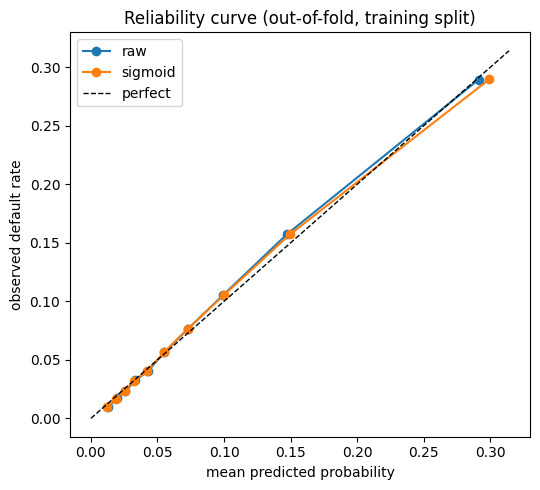

In [23]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, p in [("raw", oof), (best_kind, p_oof)]:
    frac, mean_p = calibration_curve(y_tr, p, n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", label=name)
lim = max(frac.max(), mean_p.max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1, label="perfect")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed default rate")
ax.set_title("Reliability curve (out-of-fold, training split)")
ax.legend(); plt.tight_layout(); plt.show()

## 3. Cost-based threshold

A model gives a probability of default `p`. The business needs a rule: **approve if `p` is below a cut-off.** The right cut-off depends on money, not on 0.5.

The two numbers below are **placeholder assumptions**. Replace them with your lender's real figures and say so in the README:

- `LGD`: share of the loan lost when a borrower defaults (approving a defaulter costs `LGD x loan amount`).
- `MARGIN`: profit earned on a loan that is repaid (rejecting a good customer forgoes `MARGIN x loan amount`).

Because both scale with the loan amount, the break-even probability is `MARGIN / (MARGIN + LGD)`. The notebook checks that against the empirical profit curve.

empirical best threshold: 0.136 | analytic break-even: 0.143
profit at best threshold : 8,430,980,802
profit approving everyone: 6,994,154,441
profit at threshold 0.5  : 7,191,602,034


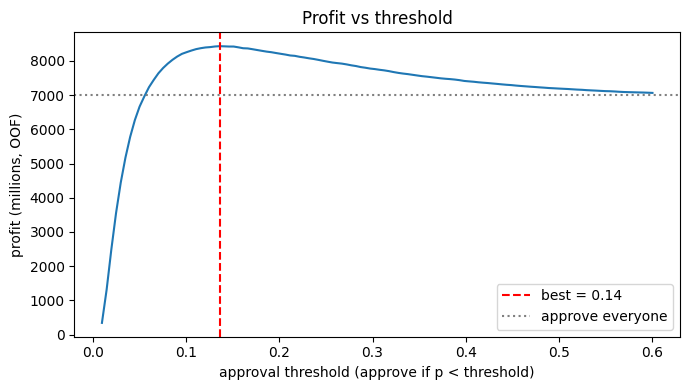

In [24]:
LGD = 0.60
MARGIN = 0.10

credit = X_train["AMT_CREDIT"].to_numpy()

def total_profit(p, y, credit, thr, lgd=LGD, margin=MARGIN):
    approve = p < thr
    per_loan = np.where(y == 0, margin * credit, -lgd * credit)
    return float(per_loan[approve].sum())

thresholds = np.linspace(0.01, 0.60, 118)
profits = np.array([total_profit(p_oof, y_tr, credit, t) for t in thresholds])
thr = float(thresholds[profits.argmax()])
analytic = MARGIN / (MARGIN + LGD)

approve_all = total_profit(p_oof, y_tr, credit, 1.01)
print(f"empirical best threshold: {thr:.3f} | analytic break-even: {analytic:.3f}")
print(f"profit at best threshold : {profits.max():,.0f}")
print(f"profit approving everyone: {approve_all:,.0f}")
print(f"profit at threshold 0.5  : {total_profit(p_oof, y_tr, credit, 0.5):,.0f}")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, profits / 1e6)
plt.axvline(thr, color="r", ls="--", label=f"best = {thr:.2f}")
plt.axhline(approve_all / 1e6, color="gray", ls=":", label="approve everyone")
plt.xlabel("approval threshold (approve if p < threshold)"); plt.ylabel("profit (millions, OOF)")
plt.title("Profit vs threshold"); plt.legend(); plt.tight_layout(); plt.show()

In [25]:
# How sensitive is the threshold to the cost assumptions?
rows = []
for lgd in [0.4, 0.6, 0.8]:
    for margin in [0.05, 0.10, 0.15]:
        pr = np.array([total_profit(p_oof, y_tr, credit, t, lgd, margin) for t in thresholds])
        t_best = thresholds[pr.argmax()]
        rows.append({"LGD": lgd, "MARGIN": margin,
                     "break_even": round(margin / (margin + lgd), 3),
                     "best_threshold": round(float(t_best), 3),
                     "approval_rate": round(float((p_oof < t_best).mean()), 3)})
print(pd.DataFrame(rows).to_string(index=False))

 LGD  MARGIN  break_even  best_threshold  approval_rate
 0.4    0.05       0.111           0.111          0.781
 0.4    0.10       0.200           0.192          0.902
 0.4    0.15       0.273           0.272          0.952
 0.6    0.05       0.077           0.071          0.641
 0.6    0.10       0.143           0.136          0.833
 0.6    0.15       0.200           0.192          0.902
 0.8    0.05       0.059           0.050          0.520
 0.8    0.10       0.111           0.111          0.781
 0.8    0.15       0.158           0.151          0.856


## 4. Final model and one-time test evaluation

The model is fitted on the full training split. The calibrator and threshold were already fixed in sections 2 and 3, so the test set has no say in them.

 scores  roc_auc  pr_auc   brier  log_loss
    raw    0.782  0.2801 0.06602    0.2383
sigmoid    0.782  0.2801 0.06602    0.2382
{'approval_rate': 0.833, 'default_rate_among_approved': 0.0474, 'default_rate_overall': 0.0807, 'defaults_rejected_pct': 0.511}
profit at chosen threshold: 2,123,367,776
profit approving everyone : 1,733,757,614
profit at threshold 0.5   : 1,791,383,261


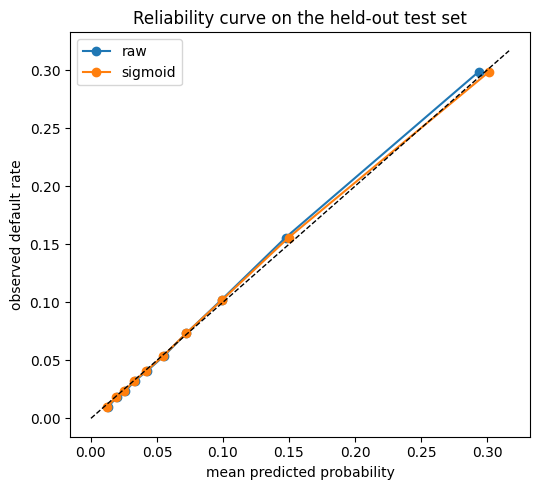

In [26]:
model = LGBMClassifier(**lgb_params).fit(X_train, y_train)
p_raw = model.predict_proba(X_test)[:, 1]
p_test = apply_calibration(p_raw, cal_params)
y_te = y_test.to_numpy()
credit_te = X_test["AMT_CREDIT"].to_numpy()

print(pd.DataFrame([report("raw", p_raw, y_te), report(best_kind, p_test, y_te)]).to_string(index=False))

approved = p_test < thr
test_summary = {
    "approval_rate": round(float(approved.mean()), 3),
    "default_rate_among_approved": round(float(y_te[approved].mean()), 4),
    "default_rate_overall": round(float(y_te.mean()), 4),
    "defaults_rejected_pct": round(float((~approved & (y_te == 1)).sum() / (y_te == 1).sum()), 3),
}
print(test_summary)
print("profit at chosen threshold:", f"{total_profit(p_test, y_te, credit_te, thr):,.0f}")
print("profit approving everyone :", f"{total_profit(p_test, y_te, credit_te, 1.01):,.0f}")
print("profit at threshold 0.5   :", f"{total_profit(p_test, y_te, credit_te, 0.5):,.0f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
for name, p in [("raw", p_raw), (best_kind, p_test)]:
    frac, mean_p = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", label=name)
lim = max(frac.max(), mean_p.max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed default rate")
ax.set_title("Reliability curve on the held-out test set"); ax.legend()
plt.tight_layout(); plt.show()

## 5. Explainability with SHAP

SHAP values show how much each feature pushed an applicant's score up or down. They are computed on the model's raw log-odds output, so use them for ranking and direction rather than as calibrated probabilities.
Text columns are shown as category codes in the beeswarm plot.

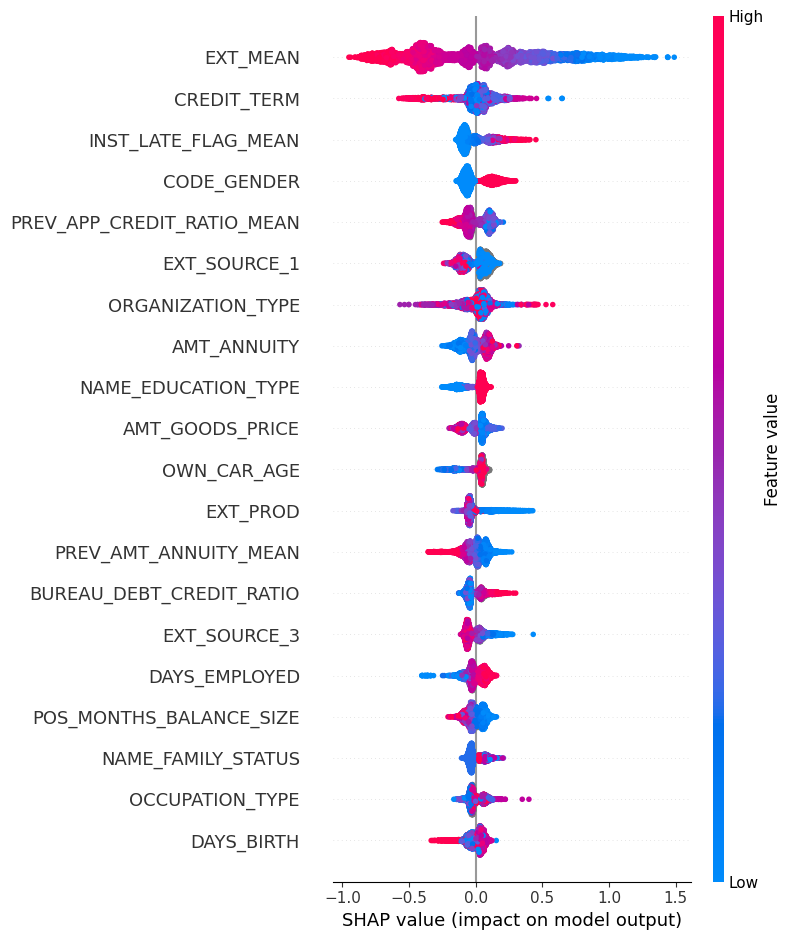

EXT_MEAN                      0.4321
CREDIT_TERM                   0.0988
INST_LATE_FLAG_MEAN           0.0964
CODE_GENDER                   0.0904
PREV_APP_CREDIT_RATIO_MEAN    0.0824
EXT_SOURCE_1                  0.0814
ORGANIZATION_TYPE             0.0803
AMT_ANNUITY                   0.0719
NAME_EDUCATION_TYPE           0.0678
AMT_GOODS_PRICE               0.0656
OWN_CAR_AGE                   0.0655
EXT_PROD                      0.0635
PREV_AMT_ANNUITY_MEAN         0.0633
BUREAU_DEBT_CREDIT_RATIO      0.0607
EXT_SOURCE_3                  0.0576


In [27]:
import shap

n_shap = min(5000, len(X_test))
sample = X_test.sample(n_shap, random_state=42)
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(sample)
if isinstance(sv, list):          # older shap versions return one array per class
    sv = sv[1]
sv = np.asarray(sv)
base = explainer.expected_value
base = float(np.ravel(base)[-1])

sample_plot = sample.copy()
for c in cat_cols:
    sample_plot[c] = sample_plot[c].cat.codes.replace(-1, np.nan)

shap.summary_plot(sv, sample_plot, max_display=20, show=True)

importance = (pd.Series(np.abs(sv).mean(axis=0), index=sample.columns)
              .sort_values(ascending=False))
print(importance.head(15).round(4).to_string())

calibrated default probability: 66.0% (approval threshold 13.6%)


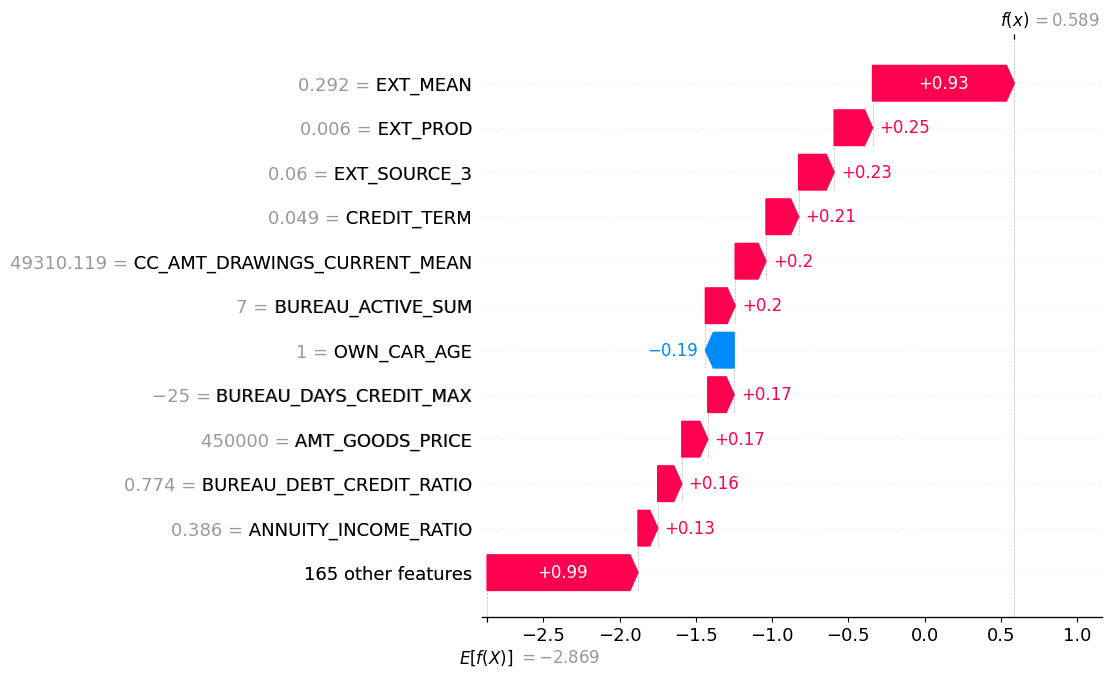

In [28]:
# Local explanation: why was the riskiest applicant in the sample flagged?
p_sample = apply_calibration(model.predict_proba(sample)[:, 1], cal_params)
i = int(np.argmax(p_sample))
print(f"calibrated default probability: {p_sample[i]:.1%} (approval threshold {thr:.1%})")
shap.plots.waterfall(
    shap.Explanation(values=sv[i], base_values=base,
                     data=sample_plot.iloc[i].to_numpy(), feature_names=list(sample.columns)),
    max_display=12, show=True)

## 6. Segment check

Compares how the model behaves across groups on the held-out test set: approval rate, predicted vs observed default rate (a calibration check per group), and ranking quality.
This is a monitoring view, not a legal fairness audit. Note that `CODE_GENDER` is an input feature in this dataset, and using gender in credit decisions is restricted in many places, so a real lender would likely drop it.

In [29]:
age_years = -X_test["DAYS_BIRTH"] / 365.25
seg = pd.DataFrame({
    "gender": X_test["CODE_GENDER"].astype(str).to_numpy(),
    "age_band": pd.cut(age_years, [0, 30, 40, 50, 60, 120],
                       labels=["<30", "30-39", "40-49", "50-59", "60+"]).astype(str).to_numpy(),
    "y": y_te, "p": p_test, "approved": approved,
})

def seg_table(col):
    rows = []
    for name, g in seg.groupby(col):
        rows.append({
            col: name, "n": len(g),
            "approval_rate": round(g["approved"].mean(), 3),
            "predicted_default": round(g["p"].mean(), 4),
            "observed_default": round(g["y"].mean(), 4),
            "roc_auc": round(roc_auc_score(g["y"], g["p"]), 3) if g["y"].nunique() == 2 else np.nan,
        })
    return pd.DataFrame(rows)

print(seg_table("gender").to_string(index=False))
print()
print(seg_table("age_band").to_string(index=False))

gender     n  approval_rate  predicted_default  observed_default  roc_auc
     F 40561          0.865             0.0710            0.0699    0.775
     M 20940          0.769             0.0999            0.1017    0.781
   XNA     2          0.500             0.1048            0.0000      NaN

age_band     n  approval_rate  predicted_default  observed_default  roc_auc
   30-39 16491          0.785             0.0952            0.0957    0.787
   40-49 15299          0.850             0.0761            0.0758    0.785
   50-59 13620          0.896             0.0627            0.0634    0.770
     60+  7188          0.947             0.0476            0.0497    0.735
     <30  8905          0.700             0.1169            0.1130    0.759


## 7. Save artifacts for Phase 4 (the API)

In [30]:
import joblib

joblib.dump(model, MODEL_DIR / "lgbm_model.joblib")
config = {
    "threshold": thr,
    "assumptions": {"LGD": LGD, "MARGIN": MARGIN},
    "calibration": cal_params,
    "feature_columns": list(X_train.columns),
    "categorical_levels": {c: [str(v) for v in X_train[c].cat.categories] for c in cat_cols},
    "lgb_params": lgb_params,
    "test_summary": test_summary,
}
with open(MODEL_DIR / "model_config.json", "w") as f:
    json.dump(config, f)
print("saved to", MODEL_DIR, ":", sorted(p.name for p in MODEL_DIR.iterdir()))

# sanity check: the saved files reproduce the test predictions
reloaded = joblib.load(MODEL_DIR / "lgbm_model.joblib")
cfg = json.load(open(MODEL_DIR / "model_config.json"))
p_check = apply_calibration(reloaded.predict_proba(X_test)[:, 1], cfg["calibration"])
assert np.allclose(p_check, p_test), "reloaded model does not reproduce test predictions"
print("reload check passed")

saved to /content/models : ['lgbm_model.joblib', 'model_config.json']
reload check passed


## README notes

Add a row to the results table, and write down the key assumptions:

- Final model: LightGBM on 176 features, calibrated with the method selected above (see the comparison table).
- Threshold chosen on out-of-fold predictions using `LGD` and `MARGIN` (placeholders, state the real ones).
- Test-set figures from section 4 are reported once, after every choice was fixed.